In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.ndimage import gaussian_filter1d
from scipy.stats import ttest_rel, wilcoxon
import scanpy as sc
sc.settings.verbosity = 0
root_dir = "./" 

In [2]:
adata = sc.read_h5ad(os.path.join(root_dir,'Data/ST/Boundary/Cell_Level_Boundary_add_Treatment_20um_Percent90.h5ad'))
adata

AnnData object with n_obs × n_vars = 4397933 × 70480
    obs: 'x_pos', 'y_pos', 'cell_ID_mask', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_reads', 'reads_per_counts', 'n_joined', 'exact_entropy', 'theoretical_entropy', 'exact_compression', 'theoretical_compression', 'cell_id', 'CellType', 'GLMPCA_leiden', 'Region', 'NMF_niche', 'region_key', 'layer', 'Layer_Niche', 'distance', 'SampleName', 'barcode', 'Sample_Leiden', 'Group'
    obsm: 'spatial', 'spatial_um'

In [5]:

def build_prop_df_from_obs(obs, niche_col="Layer_Niche", distance_col="distance", group_col="Group", celltype_col="CellType",):

    obs = obs.copy()
    obs = obs.dropna(subset=[niche_col, distance_col, group_col, celltype_col]).copy()

    for col in [niche_col, group_col, celltype_col]:
        obs[col] = obs[col].astype(str).str.strip()

    obs[distance_col] = pd.to_numeric(obs[distance_col], errors="coerce")
    obs = obs.dropna(subset=[distance_col]).copy()

    cell_types = sorted(obs[celltype_col].unique())

    total_df = (
        obs.groupby([niche_col, distance_col, group_col], as_index=False)
        .size()
        .rename(columns={"size": "total"})
    )

    count_df = (
        obs.groupby([niche_col, distance_col, group_col, celltype_col], as_index=False)
        .size()
        .rename(columns={"size": "n"})
    )

    base_grid = total_df[[niche_col, distance_col, group_col]].copy()
    base_grid["_tmp_key"] = 1

    ct_df = pd.DataFrame({celltype_col: cell_types})
    ct_df["_tmp_key"] = 1

    all_grid = base_grid.merge(ct_df, on="_tmp_key").drop(columns="_tmp_key")

    prop_df = all_grid.merge(
        count_df,
        on=[niche_col, distance_col, group_col, celltype_col],
        how="left",
        validate="many_to_one",
    )
    prop_df["n"] = prop_df["n"].fillna(0).astype(int)

    prop_df = prop_df.merge(total_df, on=[niche_col, distance_col, group_col],
        how="left",
        validate="many_to_one",
    )

    if prop_df["total"].isna().any():
        bad_keys = (
            prop_df.loc[prop_df["total"].isna(), [niche_col, distance_col, group_col]]
            .drop_duplicates()
        )
        raise ValueError(f"total merge failed, bad keys example:\n{bad_keys.head(10)}")

    prop_df["prop"] = prop_df["n"] / prop_df["total"]

    nvalid_df = total_df.groupby([niche_col, distance_col], as_index=False).size().rename(columns={"size": "n_valid_groups"})
    
    prop_df = prop_df.merge(
        nvalid_df,
        on=[niche_col, distance_col],
        how="left",
        validate="many_to_one",
    )

    return prop_df

In [6]:
 
def compute_prop_curve_data(
    prop_df,
    cell_types=None,
    niche_col="Layer_Niche",
    distance_col="distance",
    celltype_col="CellType",
    value_col="prop",
    n_valid_col="n_valid_groups",
    sigma=0.8,
):

    df_all = prop_df.copy()
    df_all = df_all.dropna(subset=[niche_col, distance_col, celltype_col, value_col]).copy()
    df_all[distance_col] = pd.to_numeric(df_all[distance_col], errors="coerce")
    df_all = df_all.dropna(subset=[distance_col]).copy()

    if cell_types is None:
        cell_types = sorted(df_all[celltype_col].unique())

    summary_records = []
 
    for target_celltype in cell_types:
        
        df_ct = df_all[df_all[celltype_col] == target_celltype].copy()

        if df_ct.empty:
            continue

        niches = sorted(df_ct[niche_col].unique())
        if len(niches) == 0:
            continue

        for niche in niches:
            dn = df_ct[df_ct[niche_col] == niche].copy()
            if dn.empty:
                continue

            distances = np.sort(dn[distance_col].unique())
            if distances.size == 0:
                continue

            tmp_rows = []

            for d in distances:
                dd = dn[dn[distance_col] == d]
                vals = dd[value_col].to_numpy(dtype=float)
                vals = vals[np.isfinite(vals)]

                if vals.size > 0:
                    med = float(np.median(vals))
                    if vals.size > 1:
                        q1 = float(np.percentile(vals, 25))
                        q3 = float(np.percentile(vals, 75))
                    else:
                        q1 = med
                        q3 = med
                else:
                    med, q1, q3 = np.nan, np.nan, np.nan

                n_valid = (
                    int(dd[n_valid_col].iloc[0])
                    if (n_valid_col in dd.columns and len(dd) > 0)
                    else int(vals.size)
                )

                tmp_rows.append(
                    {
                        "CellType": target_celltype,
                        "Layer_Niche": niche,
                        "distance": float(d),
                        "median_prop": med,
                        "q1": q1,
                        "q3": q3,
                        "n_valid_groups": n_valid,
                        "n_vals": int(vals.size),
                    }
                )

            tmp_df = pd.DataFrame(tmp_rows)
            if tmp_df.empty:
                continue

            med_arr = tmp_df["median_prop"].to_numpy(dtype=float)

            if np.all(~np.isfinite(med_arr)):
                tmp_df["median_smooth"] = np.nan
            else:
                tmp_df["median_smooth"] = gaussian_filter1d(med_arr, sigma=sigma)

            summary_records.extend(tmp_df.to_dict(orient="records"))

    summary_df = pd.DataFrame(summary_records)
 
    return summary_df

In [ ]:
def compute_curve_pvalues_from_summary(
    summary_df,
    celltype_col="CellType",
    niche_col="Layer_Niche",
    distance_col="distance",
    value_col="median_prop",
    mode="one",          # "one" or "two"
    method="paired_t",   # "paired_t" or "wilcoxon"
):
 
    records = []

    for celltype, df_ct in summary_df.groupby(celltype_col):
        df_ct = df_ct.copy()
        niches = sorted(df_ct[niche_col].dropna().unique())

        if len(niches) != 2:
            if mode == "one":
                records.append({
                    "CellType": celltype,
                    "side": "all",
                    "niche1": np.nan,
                    "niche2": np.nan,
                    "n_pairs": 0,
                    "stat": np.nan,
                    "pval": np.nan,
                    "note": f"expected 2 niches, got {len(niches)}"
                })
            else:
                for side in ["left", "right"]:
                    records.append({
                        "CellType": celltype,
                        "side": side,
                        "niche1": np.nan,
                        "niche2": np.nan,
                        "n_pairs": 0,
                        "stat": np.nan,
                        "pval": np.nan,
                        "note": f"expected 2 niches, got {len(niches)}"
                    })
            continue

        niche1, niche2 = niches

        if mode == "one":
            sub = df_ct.copy()
            side_name_list = [("all", sub)]
        elif mode == "two":
            side_name_list = [
                ("left", df_ct[df_ct[distance_col] < 0].copy()),
                ("right", df_ct[df_ct[distance_col] > 0].copy()),
            ]
        else:
            raise ValueError("mode must be 'one' or 'two'")

        for side, sub in side_name_list:
            wide = (
                sub.pivot_table(
                    index=distance_col,
                    columns=niche_col,
                    values=value_col,
                    aggfunc="first"
                )
                .dropna()
                .sort_index()
            )

            if niche1 not in wide.columns or niche2 not in wide.columns or len(wide) < 2:
                records.append({
                    "CellType": celltype,
                    "side": side,
                    "niche1": niche1,
                    "niche2": niche2,
                    "n_pairs": int(len(wide)),
                    "stat": np.nan,
                    "pval": np.nan,
                    "note": "insufficient paired distances"
                })
                continue

            x = wide[niche1].to_numpy(dtype=float)
            y = wide[niche2].to_numpy(dtype=float)

            if method == "paired_t":
                stat, pval = ttest_rel(x, y, nan_policy="omit")
            elif method == "wilcoxon":
                try:
                    stat, pval = wilcoxon(x, y)
                except ValueError:
                    stat, pval = np.nan, np.nan
            else:
                raise ValueError("method must be 'paired_t' or 'wilcoxon'")

            records.append({
                "CellType": celltype,
                "side": side,
                "niche1": niche1,
                "niche2": niche2,
                "n_pairs": int(len(wide)),
                "stat": stat,
                "pval": pval,
                "note": ""
            })

    return pd.DataFrame(records)

 
def plot_prop_curves(
    summary_df,
    pval_df=None,
    cell_types=None,
    niche_order=None,
    palette=None,
    ncols=5,
    dpi=300,
    figsize_per_panel=(3, 2.5),
    show_raw_median=True,
    show_iqr=False,
    x_label="Distance (µm)",
    y_label="Cell Proportion",
    legend_title="Status",
    fs_title=8,
    fs_axis=7,
    fs_tick=7,
    fs_legend=8,
    fs_pval=6,
):
  
    df_plot = summary_df.copy()
    df_plot["distance"] = pd.to_numeric(df_plot["distance"], errors="coerce")
    df_plot = df_plot.dropna(subset=["distance"]).copy()

    if cell_types is None:
        cell_types = sorted(df_plot["CellType"].dropna().unique())

    if niche_order is None:
        niche_order = sorted(df_plot["Layer_Niche"].dropna().unique())

    if palette is None:
        palette = ["#80b1d3", "#fdb462"]

    niche2color = {n: palette[i % len(palette)] for i, n in enumerate(niche_order)}

    n_ct = len(cell_types)
    nrows = int(np.ceil(n_ct / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(ncols * figsize_per_panel[0], nrows * figsize_per_panel[1]),
        dpi=dpi,
        sharex=False,
        sharey=False,
    )

    if n_ct == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()

    legend_dict = {}

    for ax, target_celltype in zip(axes, cell_types):
        df_ct = df_plot[df_plot["CellType"] == target_celltype].copy()

        if df_ct.empty:
            ax.set_title(target_celltype, fontsize=fs_title)
            ax.set_axis_off()
            continue

        df_ct = df_ct.sort_values(["Layer_Niche", "distance"]).copy()
        x_min = float(df_ct["distance"].min())
        x_max = float(df_ct["distance"].max())

        y_candidates = []
        
        #if "q3" in df_ct.columns and df_ct["q3"].notna().any():
        #    y_candidates.append(float(df_ct["q3"].max()))
        if df_ct["median_prop"].notna().any():
            y_candidates.append(float(df_ct["median_prop"].max()))
        #if df_ct["median_smooth"].notna().any():
        #    y_candidates.append(float(df_ct["median_smooth"].max()))

        ct_max = max(y_candidates) if len(y_candidates) > 0 else 0.0
        niches_ct = [n for n in niche_order if n in df_ct["Layer_Niche"].unique()]

        for niche in niches_ct:
            dn = df_ct[df_ct["Layer_Niche"] == niche].sort_values("distance").copy()
            if dn.empty:
                continue

            color_ = niche2color.get(niche, "#000000")

            if show_iqr and {"q1", "q3"}.issubset(dn.columns):
                if dn["q1"].notna().any() and dn["q3"].notna().any():
                    ax.fill_between(
                        dn["distance"].to_numpy(dtype=float),
                        dn["q1"].to_numpy(dtype=float),
                        dn["q3"].to_numpy(dtype=float),
                        color=color_,
                        alpha=0.15,
                        linewidth=0,
                    )

            (line_main,) = ax.plot(
                dn["distance"].to_numpy(dtype=float),
                dn["median_smooth"].to_numpy(dtype=float),
                color=color_,
                lw=1.2,
                label=niche,
            )

            if show_raw_median:
                ax.plot(
                    dn["distance"].to_numpy(dtype=float),
                    dn["median_prop"].to_numpy(dtype=float),
                    "--",
                    lw=0.7,
                    color=color_,
                    alpha=0.7,
                )

            if niche not in legend_dict:
                legend_dict[niche] = line_main

        ax.axvline(0, color="grey", lw=0.8, ls=":")
 
        if pval_df is not None and len(pval_df) > 0:
            sub_p = pval_df[pval_df["CellType"] == target_celltype].copy()

            if len(sub_p) > 0 and "side" in sub_p.columns and "pval" in sub_p.columns:
                sides = sorted(sub_p["side"].dropna().unique())
 
                if sides == ["all"]:
                    pval = sub_p["pval"].iloc[0]
                    if pd.notna(pval):
                        txt = f"p = {pval:.2g}"
                        ax.text(
                            0.03, 0.97, txt,
                            transform=ax.transAxes,
                            ha="left", va="top",
                            fontsize=fs_pval, color="black"
                        )
                else:
                    p_left = sub_p.loc[sub_p["side"] == "left", "pval"]
                    p_right = sub_p.loc[sub_p["side"] == "right", "pval"]

                    if len(p_left) > 0 and pd.notna(p_left.iloc[0]):
                        ax.text(
                            0.03, 0.95, f"p = {p_left.iloc[0]:.2g}",
                            transform=ax.transAxes,
                            ha="left", va="top",
                            fontsize=fs_pval, color="black"
                        )

                    if len(p_right) > 0 and pd.notna(p_right.iloc[0]):
                        ax.text(
                            0.97, 0.95, f"p = {p_right.iloc[0]:.2g}",
                            transform=ax.transAxes,
                            ha="right", va="top",
                            fontsize=fs_pval, color="black"
                        )

        ymax_ct = ct_max * 1.1 if ct_max > 0 else 1.0
        ax.set_ylim(0, ymax_ct)
        ax.set_xlim(x_min, x_max)
        ax.set_xlabel(x_label, fontsize=fs_axis)
        ax.set_ylabel(y_label, fontsize=fs_axis)
        ax.tick_params(axis="both", which="major", labelsize=fs_tick)
        ax.grid(False)
        ax.set_title(str(target_celltype), fontsize=fs_title)

    for ax in axes[n_ct:]:
        ax.set_axis_off()

    if len(legend_dict) > 0:
        handles = list(legend_dict.values())
        labels = list(legend_dict.keys())
        leg = fig.legend(
            handles,
            labels,
            loc="upper right",
            bbox_to_anchor=(0.99, 0.65),
            fontsize=fs_legend,
            title=legend_title,
        )
        leg.get_title().set_fontsize(fs_legend)

    plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95])
    return fig, axes

In [ ]:
distance_min=-20
distance_max=500

obs = adata.obs[["Layer_Niche", "distance", "Group", "CellType"]].copy()
obs = obs.loc[(obs["distance"] >= distance_min) & (obs["distance"] <= distance_max)].copy()
obs = obs.loc[obs["Layer_Niche"].isin(["NR-like", "R-like"])].copy()
obs = obs.loc[~((obs["CellType"] == "Epithelial") & (obs["distance"] > 0))].copy() 
obs = obs.loc[~((obs["CellType"] == "Hepatocyte") & (obs["distance"] > 0))].copy() 
obs = obs.loc[obs["CellType"] != "conflict"].copy()

prop_df = build_prop_df_from_obs(obs)
prop_df = prop_df[prop_df['n_valid_groups']>=5]
summary_df = compute_prop_curve_data(prop_df=prop_df,   sigma=0.8,)
pval_df = compute_curve_pvalues_from_summary(summary_df, value_col="median_prop", mode="two", method="paired_t")


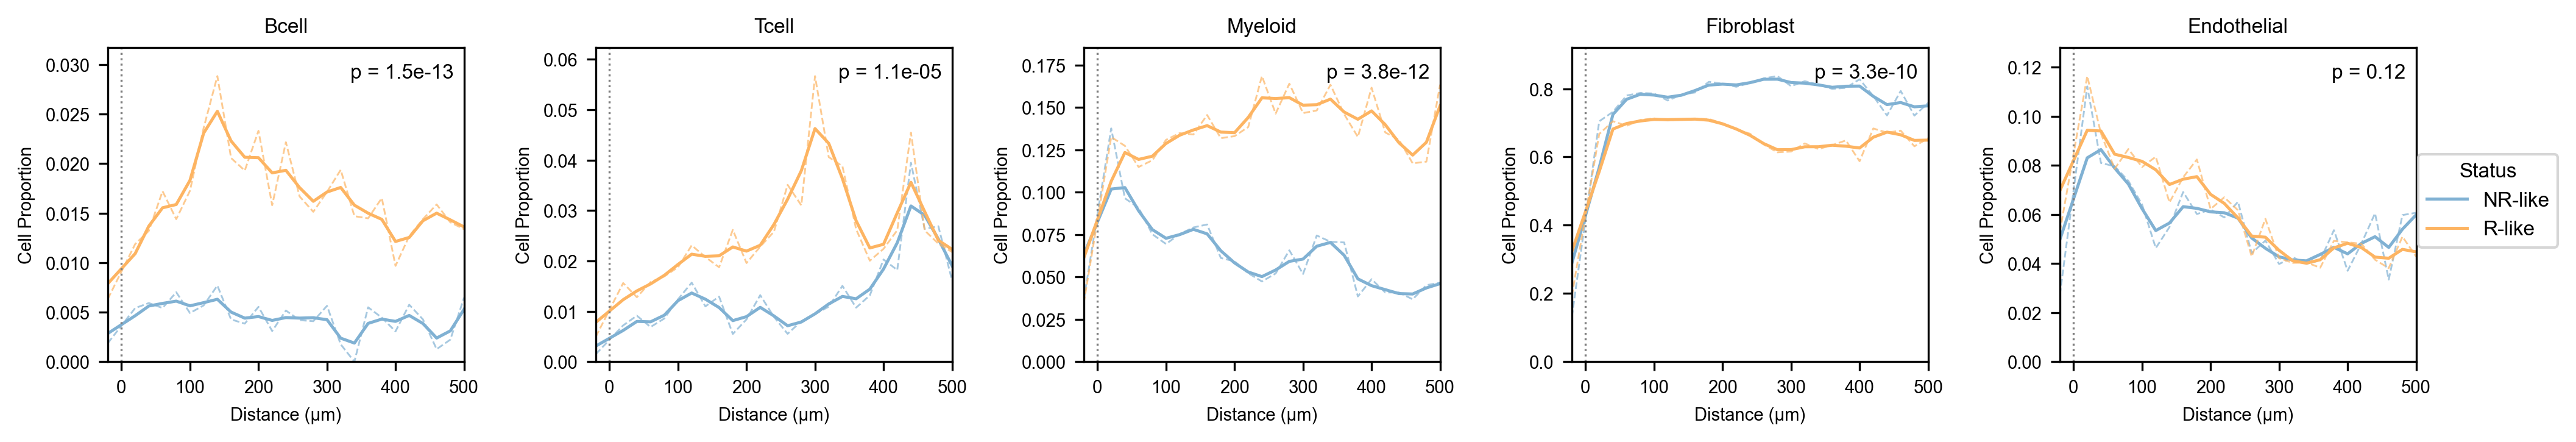

In [11]:
 
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["text.usetex"] = False
fig, axes = plot_prop_curves(
    summary_df=summary_df,
    pval_df=pval_df,
    cell_types=["Bcell", "Tcell", "Myeloid","Fibroblast", "Endothelial" ],
    niche_order=["NR-like", "R-like"],
    palette=["#80b1d3", "#fdb462"],
    ncols=5,
    show_raw_median=True,
    show_iqr=False,
    figsize_per_panel=(3,2.8),
    fs_pval=8,
)
fig.savefig("/Volumes/B/Projects/2025Project/SpatialAnalysis/Project_ICC/Figure/ST/Boundary/2_cell_proportion_curves_patient_paired_Final.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()